In [1]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#in this code let's use train an AI to play a game of battleship
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@

In [2]:
#@@@@@@@@@@@@@@@@@@@@@@@
#import useful libraries
#@@@@@@@@@@@@@@@@@@@@@@@
import numpy as np
import copy
import seaborn as sb

from tqdm import tqdm
from IPython.display import clear_output
import time
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

import pickle


In [3]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#two classes for these two environments
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class Battleship:
    '''A class to manage the board'''
    
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config
        self.hit_streak = 0
        self.last_hit_coordinate = None    #(row, col) of the latest hit on a ship not yet sunk
        self.true_state = np.zeros([config['n'],config['n']],dtype = int)
        self.ship_cells = []    #list of (rows, cols) index arrays, one per ship
        self.state = np.zeros([config['n'],config['n']],dtype = int)    #TODO -- consider how to change this
        self.old_state = copy.deepcopy(self.state)

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def position_maker(self,ship):
        '''A function to choose a position for a ship
            Takes:
                self -- class instance info above
                ship -- int, the index in the list of ship lengths
            Returns:
                an int, int pair, the coordinates of the first cell the ship occupies
        '''
        coord_1 = np.random.choice(list(range(self.config['n'] - self.config['ships'][ship] + 1)))    #choose first coordinate, guaranteed to have ship on board
        coord_2 = np.random.choice(list(range(self.config['n'])))    #choose second coordinate
        return coord_1,coord_2

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def check_empty(self,coord_1,coord_2,vert,ship):
        '''A function to make sure the proposed location is currently empty
            Takes:
                self -- class instance info above
                coord_1 -- int, the first coordinate, constrained to ensure the ship lies on the board
                coord_2 -- int, the second coordinate
                vert -- boolean, whether to orient the ship vertically or horizontally
                ship -- int, the index in the list of ship lengths
            Returns:
                a boolean, indicating if the placement is legal
        '''
        if vert:    #if the ship is oriented vertically...
            if sum(self.true_state[coord_1 + list(range(self.config['ships'][ship])),coord_2]) > 0:    #and if there is another ship lying across its path...
                empty = False    #set the empty indicator to false
            else:    #otherwise if the proposed location is empty...
                empty = True    #set the empty indicator to true
        else:    #if the ship is oriented horizontally...
            if sum(self.true_state[coord_2,coord_1 + list(range(self.config['ships'][ship]))]) > 0:    #and if there is anther ship lying across its path...
                empty = False    #set the empty indicator to false
            else:    #otherwise if the proposed location is empty...
                empty = True    #set the empty indicator to true
        return empty

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def place_ship(self,ship):
        '''A function to put a single ship on the board
            Takes:
                self -- class instance info above
                ship -- int, the index in the list of ship lengths
        '''
        empty = False    #init the stopping criterion
        while not empty:    #while we should keep going...
            coord_1,coord_2 = self.position_maker(ship)    #sample a position for the ship
            vert = np.random.uniform() < 0.5    #choose whether ship is horizontal or vertical
            empty = self.check_empty(coord_1,coord_2,vert,ship)    #check if legal
        span = coord_1 + np.arange(self.config['ships'][ship])    #cells along the ship's length
        if vert:    #if the ship is vertical...
            cells = (span, np.full(len(span), coord_2))
        else:    #if the ship is horizontal...
            cells = (np.full(len(span), coord_2), span)
        self.true_state[cells] = 1    #place on board
        self.ship_cells.append(cells)    #remember where this ship is
        vert = np.random.uniform() < 0.5    #choose whether ship is horizontal or vertical

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def make_board(self):
        '''A function to put all ships on the board
            Takes:
                self -- class instance info above
        '''
        self.true_state = np.zeros([self.config['n'],self.config['n']],dtype = int)
        self.ship_cells = []    #clear old ship locations
        for j in range(len(self.config['ships'])):    #loop over ship lengths
            self.place_ship(j)    #put on board'

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reset(self):
        '''A function to reset the board
            Takes:
                self -- class instance info above
        '''
        self.hit_streak = 0
        self.last_hit_coordinate = None    #no hit yet this game
        self.true_state = np.zeros([self.config['n'],self.config['n']],dtype = int)    #reset the hidden state
        self.make_board()    #place ships again
        self.state = np.zeros([self.config['n'],self.config['n']],dtype = int)    #reset the observed state
        self.old_state = copy.deepcopy(self.state)
        

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def check_win(self):
        '''A function to check whether the agent has won
            Takes:
                self -- class instance info above
            Returns:
                a boolean, indicating if the agent sank all the ships
        '''
        if np.sum(self.state>0) == sum(self.config['ships']):    #if the number of hits is equal to the total length of ships...
            return True    #return true -- the agent won!
        else:    #otherwise...
            return False    #return false -- the game is still going

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def ships_remaining(self):
        '''A function to find which ships have not been sunk yet
            Takes:
                self -- class instance info above
            Returns:
                a tuple of ints, the lengths of the ships still afloat
        '''
        return tuple(length for length, cells in zip(self.config['ships'], self.ship_cells)
                     if not np.all(self.state[cells] == 1))    #afloat if any cell is not yet hit

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def get_state(self):
        '''A function to build the state the agent observes
            Takes:
                self -- class instance info above
            Returns:
                a tuple (board, ships_left), hashable so it can be used as a Q-table key
                    board -- tuple of tuples, 1 = hit, -1 = miss, 0 = not yet targeted
                    ships_left -- tuple of ints, the lengths of ships not yet sunk
        '''
        board = tuple(map(tuple, self.state))    #hits and misses on the observed board
        return (board, self.ships_remaining())

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def reward(self,):
        #TODO
        a = self.last_action    #the action just taken, set in step
        # Penalize shots already taken
        if self.old_state[a['row'],a['col']] != 0:
            return self.config.get('repeat_penalty', -1)
        r = 0
        # Reward shooting next to the last hit (up, down, left, right), even on a miss
        if self.last_hit_coordinate is not None:
            last_row, last_col = self.last_hit_coordinate
            if abs(a['row'] - last_row) + abs(a['col'] - last_col) == 1:    #exactly 1 tile away, no diagonals
                r += self.config.get('adjacent_reward', 1)
        # Reward for hitting
        if self.state[a['row'],a['col']] == 1:
            r += self.config.get('hit_reward', 1)
            self.last_hit_coordinate = (a['row'], a['col'])    #remember the latest hit
            for cells in self.ship_cells:    #find the ship that was hit...
                if np.any((cells[0] == a['row']) & (cells[1] == a['col'])) and np.all(self.state[cells] == 1):    #...and if this hit sank it...
                    self.last_hit_coordinate = None    #ship destroyed, nothing to follow up on
            return r
        return r + self.config.get('miss_reward', 0)
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def step(self,a):
        '''A function to update the state given the true enemy fleet locations'''
        if self.true_state[a['row'],a['col']] > 0:    #if there is a ship at the chosen location...
            self.state[a['row'],a['col']] = 1    #record a hit on the observed state as a 1
        else:    #if there is no ship
            self.state[a['row'],a['col']] = -1    #record a miss on the observed state as a -1
        done = self.check_win()    #check to see if the agent has won
        if done:
            r = 10#max(10*np.sum(self.state == 0),10)
        else:
            self.last_action = a    #let reward() see the action
            r = self.reward()    #WILL NOT WORK RIGHT NOW -- NEED TO SPECIFIY REWARD FUNCTION
        self.old_state = copy.deepcopy(self.state)
        return{'state':self.get_state(),'reward':r,'done':done}
        

In [4]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#A simple CNN architecture
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        # Input: (batch_size, 1, 6, 6)
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)  # -> (32, 6, 6)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)  # -> (64, 6, 6)
        self.conv3 = nn.Conv2d(64, 1, kernel_size=1)  # -> (1, 6, 6)

    def forward(self, x):
        x = F.relu(self.conv1(x))  # (batch_size, 32, 6, 6)
        x = F.relu(self.conv2(x))  # (batch_size, 64, 6, 6)
        q_map = self.conv3(x)      # (batch_size, 1, 6, 6)
        return q_map.squeeze(1)    # -> (batch_size, 6, 6)


In [5]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
from collections import deque

class Agent:
    '''A class to manage the chase'''
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config):
        '''Set up the constructor
            Takes -- config, a dictionary specifying the track dimensions and initial state
        '''
        self.config = config    #save the config file
        self.A_s = self.config['A']    #save the action set
        #init the deep learning model
        self.Q = CNN()    #Q(s,.|w)
        self.optimizer = optim.Adam(self.Q.parameters(), lr=self.config['alpha'])    #takes the gradient steps
        #copy the target approximator
        self.Q_target = copy.deepcopy(self.Q)    #w' = w
        #init the replay buffer
        self.replay_buffer = deque()    #holds (s, a, r, s', done) tuples
        self.n_updates = 0    #number of gradient steps taken, used to time target updates

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def update_Q_target(self,):
        '''A function to update the target approximator
        '''
        #TODO
        self.Q_target.load_state_dict(self.Q.state_dict())    #w' <- w
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def purge_replay_buffer(self,):
        '''A function to keep the replay buffer within memory limits
        '''
        #TODO
        while len(self.replay_buffer) > self.config['M']:    #if |D| > M...
            self.replay_buffer.popleft()    #drop the oldest
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def forward_pass(self, s, model=None):
        '''A function to compute the forward pass
        '''
        #TODO
        if model is None:    #default to the main approximator
            model = self.Q
        x = torch.as_tensor(np.array(s), dtype=torch.float32)
        if x.dim() == 2:    #a single board...
            x = x.unsqueeze(0)    #...becomes a batch of one
        q_map = model(x.unsqueeze(1))    #add the channel dimension -> (B, 1, n, n)
        return q_map.reshape(q_map.shape[0], -1)    #(B, n*n), index row*n + col matches A
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@    
    def pi(self, s):
        '''A function to choose actions using Q-values
        '''
        #TODO
        if np.random.uniform() < self.config['epsilon']:    #with probability epsilon...
            return np.random.randint(len(self.A_s))    #explore: uniform over all actions
        with torch.no_grad():
            return int(torch.argmax(self.forward_pass(s)[0]))    #exploit: argmax_a Q(s,a|w)
        
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def make_batch(self):
        '''A function to make a batch for updating Q
        '''
        #TODO
        idx = np.random.choice(len(self.replay_buffer), self.config['B'], replace=False)    #sample B tuples uniformly
        s, a, r, s_prime, done = zip(*[self.replay_buffer[i] for i in idx])
        return (np.array(s),
                torch.as_tensor(a, dtype=torch.long),
                torch.as_tensor(r, dtype=torch.float32),
                np.array(s_prime),
                torch.as_tensor(done, dtype=torch.float32))

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def update_Q_value(self,):
        '''A function to use the batch to estimate the gradient and take a single step
        '''
        #TODO
        if len(self.replay_buffer) < self.config['B']:    #only update once |D| >= B
            return
        s, a, r, s_prime, done = self.make_batch()    #choose batch
        with torch.no_grad():    #targets come from the target approximator
            max_q_next = self.forward_pass(s_prime, self.Q_target).max(dim=1).values
            y = r + self.config['gamma'] * max_q_next * (1 - done)    #y_j, 0 future value if terminal
        q_sa = self.forward_pass(s).gather(1, a.unsqueeze(1)).squeeze(1)    #Q(s_j, a_j|w)
        loss = F.mse_loss(q_sa, y)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()    #take a single gradient step
        self.n_updates += 1
        if self.n_updates % self.config['C'] == 0:    #every C steps...
            self.update_Q_target()    #...w' <- w

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def add_to_replay_buffer(self, s, a, r, s_prime, done):
        '''A function to store a transition (s, a, r, s', done) in the replay buffer
            Takes:
                s, s_prime -- the board before and after the action (n x n arrays)
                a -- int, the index of the action taken
                r -- the reward received
                done -- boolean, whether s_prime is terminal
        '''
        self.replay_buffer.append((np.array(s), a, r, np.array(s_prime), done))
        self.purge_replay_buffer()

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def action_to_dict(self, a):
        '''A function to convert an action index into the dict Battleship.step expects'''
        row, col = self.A_s[a]
        return {'row': row, 'col': col}
        


In [6]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Classical Q-learning agent (tabular)
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
class QAgent:
    '''A class to manage a tabular Q-learning agent'''
    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def __init__(self, config, state_rep='full'):
        '''Set up the constructor
            Takes -- config, a dictionary with 'epsilon', 'gamma', 'alpha', and the action set 'A'
                     state_rep, which state the agent uses:
                        'board' -- only the current board (hits/misses/untargeted)
                        'full' -- the hand-built state: the board plus the lengths of ships still afloat
        '''
        if state_rep not in ('board', 'full'):
            raise ValueError("state_rep must be 'board' or 'full'")
        self.state_rep = state_rep    #save which state representation to use
        self.config = config    #save the config file
        self.A_s = self.config['A']    #save the action set
        self.epsilon = self.config['epsilon']    #probability of exploring
        self.gamma = self.config['gamma']    #discount factor
        self.alpha = self.config['alpha']    #learning rate
        self.Q = {}    #the Q-table: state -> array of Q-values, one per action

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def make_state(self, s):
        '''A function to reduce the environment's state to the agent's state representation
            Takes:
                s -- the state from Battleship.get_state, (board, ships_left)
            Returns:
                the hashable state used as the Q-table key
        '''
        if self.state_rep == 'board':    #board-only agent...
            return s[0]    #...ignores which ships are left
        return s    #full agent uses the whole hand-built state

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def get_Q(self, s):
        '''A function to look up the Q-values for a state
            Takes:
                s -- the state from Battleship.get_state
            Returns:
                an array of Q-values, one per action, initialized to 0 for unseen states
        '''
        s = self.make_state(s)    #use this agent's state representation
        if s not in self.Q:    #if we haven't seen this state yet...
            self.Q[s] = np.zeros(len(self.A_s))    #init its Q-values
        return self.Q[s]

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def pi(self, s):
        '''A function to choose actions epsilon-greedily using Q-values
            Takes:
                s -- the state from Battleship.get_state
            Returns:
                an int, the index of the chosen action in the action set
        '''
        if np.random.uniform() < self.epsilon:    #with probability epsilon...
            return np.random.randint(len(self.A_s))    #explore: uniform over all actions
        q = self.get_Q(s)
        best = np.flatnonzero(q == q.max())    #all actions tied for the best Q-value
        return np.random.choice(best)    #exploit: break ties at random

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def action_to_dict(self, a):
        '''A function to convert an action index into the dict Battleship.step expects'''
        row, col = self.A_s[a]
        return {'row': row, 'col': col}

    #@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
    def update_Q(self, s, a, r, s_prime):
        '''A function to apply the Q-learning update rule
            Q(s,a) <- Q(s,a) + alpha * [r + gamma * max_a' Q(s',a') - Q(s,a)]
            Takes:
                s -- the state the action was taken in
                a -- int, the index of the action taken
                r -- the reward received
                s_prime -- the state after the action
        '''
        q = self.get_Q(s)
        td_error = r + self.gamma * np.max(self.get_Q(s_prime)) - q[a]    #TD error for s,a
        q[a] += self.alpha * td_error    #step toward the target


In [7]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Set up the classes -- the environment and the agent
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
env_config = {'n':6,'ships':[2,3,4],'boards':None}    #set up the environmental config

A = []    #init the actions
for row in range(6):    #loop over vertical velo changes
    for col in range(6):    #loop over horizonal velo changes
        A.append([row,col])    #record

agent_config = {'gamma':0.9    #the discount factor
                ,'epsilon':0.1    #the epsilon-greedy parameter
                ,'alpha':0.001    #the learning rate
                ,'A':A    #the action set
                ,'n':6    #the size of the board
                ,'M':100000    #set the memory size
                ,'B':32    #set the batch size
                ,'C':500    #when to update the target approximator
                ,'n_steps_for_Q_update':4    #the number of steps to use to update
               }   #examples of agent config

board = Battleship(env_config)    #set up the environment for testing agent performance
agent = Agent(agent_config)    #set up the agent


In [8]:
#@@@@@@@@@@@@@
#Training Loop
#@@@@@@@@@@@@@
import random
N_eps = 1000
game_lengths = []    #record the number of turns each game takes
for epi in tqdm(range(N_eps)):    #loop over episodes
    board.make_board()    #set up the board
    done = False    #set the stopping condition
    turn = 0    #init the turn count
    while not done:#for _ in range(6):    #while the episode goes on...
        #TODO
        #generate an action
        row = random.randint(0,agent_config["n"] - 1)
        col = random.randint(0,agent_config["n"] - 1)
        action = {
            "row": row,
            "col": col
        }
        step_results = board.step(action)

        done = step_results["done"]
        turn += 1 
        
        #init the tuple for this turn
        #save the old state
        #save the action
        #evolve the environment
        #save the reward
        #save the new state
        
        #add this tuple to the replay buffer
        #remove the oldest tuple if appropriate
        
        #record whether we've stopped

        #update the Q values
        #update the target approximator

    game_lengths.append(turn)    #record the game length
    board.reset()    #reset the board
    

  0%|          | 0/1000 [00:00<?, ?it/s]

  1%|          | 10/1000 [00:00<00:09, 99.37it/s]

  2%|▎         | 25/1000 [00:00<00:07, 127.34it/s]

  4%|▍         | 38/1000 [00:00<00:08, 113.48it/s]

  5%|▌         | 51/1000 [00:00<00:07, 118.66it/s]

  7%|▋         | 69/1000 [00:00<00:06, 138.30it/s]

... (45 outputs left out)

 95%|█████████▍| 948/1000 [00:05<00:00, 202.98it/s]

 97%|█████████▋| 969/1000 [00:05<00:00, 200.82it/s]

 99%|█████████▉| 991/1000 [00:05<00:00, 206.22it/s]

100%|██████████| 1000/1000 [00:06<00:00, 166.34it/s]

/tmp/ipykernel_324038/1403831615.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


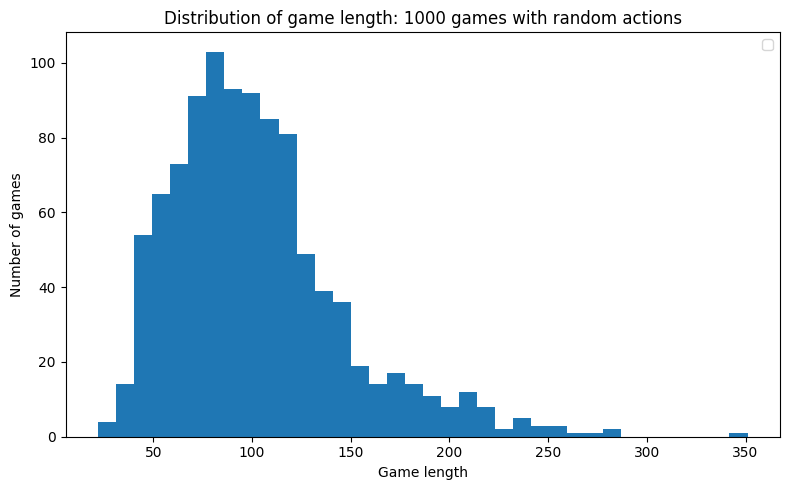

In [9]:
game_lengths = np.array(game_lengths)

plt.figure(figsize=(8,5))
plt.hist(game_lengths, bins=36)
plt.xlabel('Game length')
plt.ylabel('Number of games')
plt.title(f'Distribution of game length: {N_eps} games with random actions')
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
#Train the two classical Q-learning agents in parallel
#  'board' -- uses only the current board as the state
#  'full'  -- uses the hand-built state (board + ships still afloat)
#@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@@
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

q_config = {'gamma':0.9    #the discount factor
            ,'epsilon':1.0    #starting epsilon, decayed during training
            ,'alpha':0.1    #the learning rate
            ,'A':A    #the action set
           }
N_train = 6000    #number of training episodes
eps_start, eps_end = 1.0, 0.05    #epsilon decays linearly from eps_start to eps_end
repeat_penalty = -1    #reward for firing at a cell that was already targeted

def train_q_agent(state_rep, seed):
    '''A function to train one QAgent
        Takes:
            state_rep -- 'board' or 'full', passed to QAgent
            seed -- int, random seed for this process
        Returns:
            state_rep, the trained agent, and arrays of total reward and turns per episode
    '''
    np.random.seed(seed)    #each process needs its own random stream
    env = Battleship({**env_config, 'repeat_penalty': repeat_penalty})    #each process gets its own board
    q_agent = QAgent(dict(q_config), state_rep=state_rep)
    rewards, turns = [], []
    for epi in range(N_train):    #loop over episodes
        q_agent.epsilon = eps_start + (eps_end - eps_start) * epi / (N_train - 1)    #decay epsilon
        env.reset()    #new board
        s = env.get_state()
        done, total_r, t = False, 0, 0
        while not done:    #while the episode goes on...
            a = q_agent.pi(s)    #choose an action
            out = env.step(q_agent.action_to_dict(a))    #evolve the environment
            q_agent.update_Q(s, a, out['reward'], out['state'])    #Q-learning update
            s = out['state']
            done = out['done']
            total_r += out['reward']
            t += 1
        rewards.append(total_r)
        turns.append(t)
    return state_rep, q_agent, np.array(rewards), np.array(turns)

#run both agents at the same time, one process each
with ProcessPoolExecutor(max_workers=2, mp_context=mp.get_context('fork')) as pool:
    futures = [pool.submit(train_q_agent, rep, seed) for seed, rep in enumerate(['board', 'full'])]
    q_results = {}
    for f in futures:
        rep, trained_agent, rewards, turns = f.result()
        q_results[rep] = {'agent': trained_agent, 'rewards': rewards, 'turns': turns}

for rep, res in q_results.items():
    print(f"{rep}: last 500 episodes -- avg reward = {res['rewards'][-500:].mean():.2f}, "
          f"avg turns = {res['turns'][-500:].mean():.2f}, states in Q-table = {len(res['agent'].Q)}")


board: last 500 episodes -- avg reward = -31.28, avg turns = 85.91, states in Q-table = 183181
full: last 500 episodes -- avg reward = -31.83, avg turns = 86.32, states in Q-table = 204603
